<div style = "border: 1px solid black">
<b><center><font size = "5"> Mini-Projeto </font><center></b>

</font><center></b>
</div>



---



`Nome:` Leonor Rebola <br>
`Número:` 53663 <br>
`Email:` leonor.rebola@ubi.pt <br>

`Nome:` Adriana Abreu <br>
`Número:` 53672 <br>
`Email:` adriana.abreu@ubi.pt <br>

`Curso:` Inteligência Artificial e Ciência de Dados <br>
`UC:` Análise de Dados <br>


---



In [ ]:
import seaborn as sns, matplotlib.pyplot as plt, pandas as pd, numpy as np
from scipy import stats

ans = sns.load_dataset('anscombe')
pen = sns.load_dataset('penguins')

In [ ]:
cores = {'Adelie': '#E69F00', 'Chinstrap': '#CC79A7', 'Gentoo': '#0072B2'}
ordem = ['Adelie', 'Chinstrap', 'Gentoo']

# **Exercício 1**

---



a) Para cada um dos 4 conjuntos, calcule média de x, média de y, correlação e a reta de regressão. Apresente numa tabela única (dica: groupby('dataset')).

,media_x,media_y,correlacao,declive,ordenada
dataset,,,,,
I,9.0,7.501,0.816,0.5,3.000
II,9.0,7.501,0.816,0.5,3.001
III,9.0,7.500,0.816,0.5,3.002
IV,9.0,7.501,0.817,0.5,3.002


As 4 tabelas têm estatísticas praticamente idênticas: média de x = 9, média de y ≈ 7,5, correlação ≈ 0,82 e reta y ≈ 3 + 0,5x. Só pelos números, os conjuntos pareceriam iguais.

b) Construa a grelha 2×2 de scatter plots (um por conjunto), com a reta de regressão sobreposta (sns.lmplot com col='dataset').

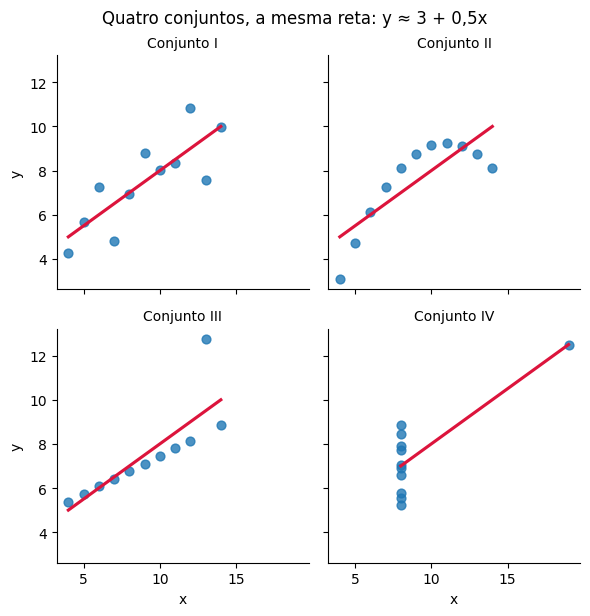

In [ ]:
g = sns.lmplot(data=ans, x='x', y='y', col='dataset', col_wrap=2,
               height=3, ci=None,
               scatter_kws={'s': 40}, line_kws={'color': 'crimson'})
g.set_titles('Conjunto {col_name}')
g.figure.suptitle('Quatro conjuntos, a mesma reta: y ≈ 3 + 0,5x', y=1.02)
plt.show()

Só o conjunto I é uma relação linear com ruído. O II é uma curva (parábola), o III é linear com um outlier que desvia a reta, e o IV tem todos os x iguais menos um ponto de alavanca que sozinho define a reta.

c) Em Markdown (3–4 linhas): que lição prática retira para o seu fluxo de trabalho de análise?

As estatísticas descritivas resumem os dados, mas não os substituem: conjuntos muito diferentes podem dar médias, correlações e retas iguais. Por isso devo visualizar sempre os dados antes de modelar, e não confiar só em números-resumo. O gráfico revela não-linearidade, outliers e pontos de alavanca que os números escondem. No meu fluxo de trabalho, o scatter plot e o histograma vêm antes do describe() e da regressão.

# **Exercício 2**

---



a) Distribuição: compare a massa corporal por espécie com violinos ou boxplots.

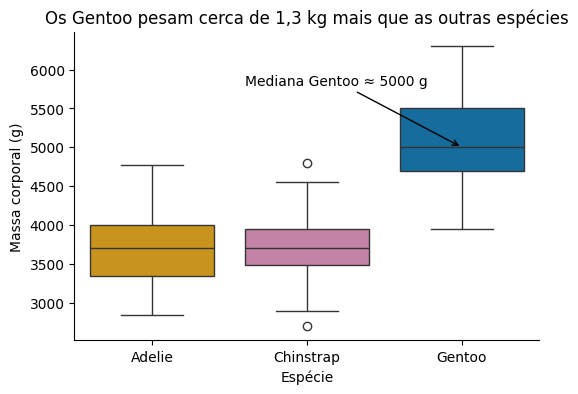

In [ ]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.boxplot(data=pen, x='species', y='body_mass_g', order=ordem,
            hue='species', palette=cores, legend=False, ax=ax)
ax.set_title('Os Gentoo pesam cerca de 1,3 kg mais que as outras espécies')
ax.set_xlabel('Espécie')
ax.set_ylabel('Massa corporal (g)')
ax.annotate('Mediana Gentoo ≈ 5000 g', xy=(2, 5000), xytext=(0.6, 5800),
            arrowprops=dict(arrowstyle='->'))
sns.despine()
plt.show()

A mediana da massa é 3700 g nos Adelie e Chinstrap e 5000 g nos Gentoo. As duas primeiras espécies têm distribuições quase sobrepostas, e os Gentoo estão claramente separados. Usei boxplots porque mostram mediana, dispersão e outliers de forma compacta e permitem comparar grupos.

b) Relação: comprimento vs profundidade do bico, colorido por espécie — comente o paradoxo de Simpson visual que aparece quando se ignora a espécie.

Correlação global: -0.235
species
Adelie       0.391
Chinstrap    0.654
Gentoo       0.643
dtype: float64


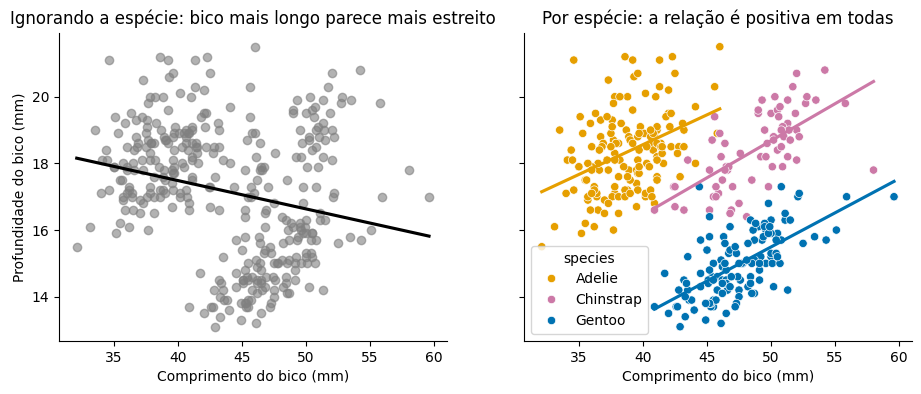

In [ ]:
d = pen.dropna(subset=['bill_length_mm', 'bill_depth_mm'])
print('Correlação global:', round(d.bill_length_mm.corr(d.bill_depth_mm), 3))
print(d.groupby('species')
        .apply(lambda g: g.bill_length_mm.corr(g.bill_depth_mm), include_groups=False)
        .round(3))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4), sharex=True, sharey=True)

# Ignorando a espécie
a1.scatter(d.bill_length_mm, d.bill_depth_mm, color='grey', alpha=.6)
sns.regplot(data=d, x='bill_length_mm', y='bill_depth_mm',
            scatter=False, color='black', ci=None, ax=a1)
a1.set_title('Ignorando a espécie: bico mais longo parece mais estreito')

# Por espécie
sns.scatterplot(data=d, x='bill_length_mm', y='bill_depth_mm',
                hue='species', palette=cores, ax=a2)
for sp, gr in d.groupby('species'):
    sns.regplot(data=gr, x='bill_length_mm', y='bill_depth_mm',
                scatter=False, color=cores[sp], ci=None, ax=a2)
a2.set_title('Por espécie: a relação é positiva em todas')

for a in (a1, a2):
    a.set_xlabel('Comprimento do bico (mm)')
    a.set_ylabel('Profundidade do bico (mm)')
sns.despine()
plt.show()

Ao juntar todos os pinguins, a reta desce (r = −0,24): parece que bicos mais longos são menos profundos. Mas dentro de cada espécie a relação é positiva (r entre 0,39 e 0,65). Isto é o paradoxo de Simpson: a tendência global inverte-se quando se separa por uma variável de confusão, aqui a espécie. Os Gentoo têm bicos longos mas pouco profundos e puxam a reta global para baixo. Ignorar a espécie leva a uma conclusão errada.

c) Comparação: n.º de pinguins por ilha em barras ordenadas por valor.

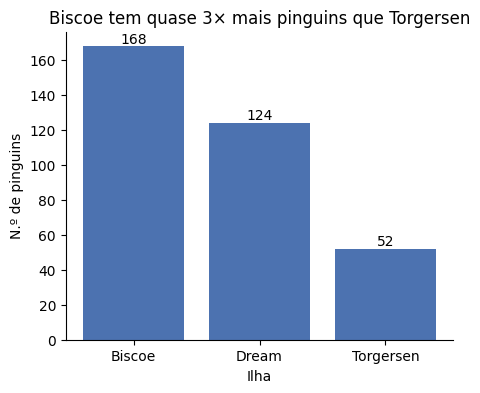

In [ ]:
ilhas = pen['island'].value_counts()

fig, ax = plt.subplots(figsize=(5, 4))
ax.bar(ilhas.index, ilhas.values, color='#4C72B0')
for i, v in enumerate(ilhas.values):
    ax.text(i, v + 2, v, ha='center')
ax.set_title('Biscoe tem quase 3× mais pinguins que Torgersen')
ax.set_xlabel('Ilha')
ax.set_ylabel('N.º de pinguins')
sns.despine()
plt.show()

Biscoe tem 168 pinguins, Dream 124 e Torgersen 52 pinguins.

Ordenei as barras por valor para facilitar a comparação. O eixo parte do zero, porque nas barras o comprimento representa o valor. Os rótulos diretos dispensam a grelha.

d) Painel: junte (a)–(c) numa figura única com plt.subplots, limpa de chartjunk (despine, grelha mínima).

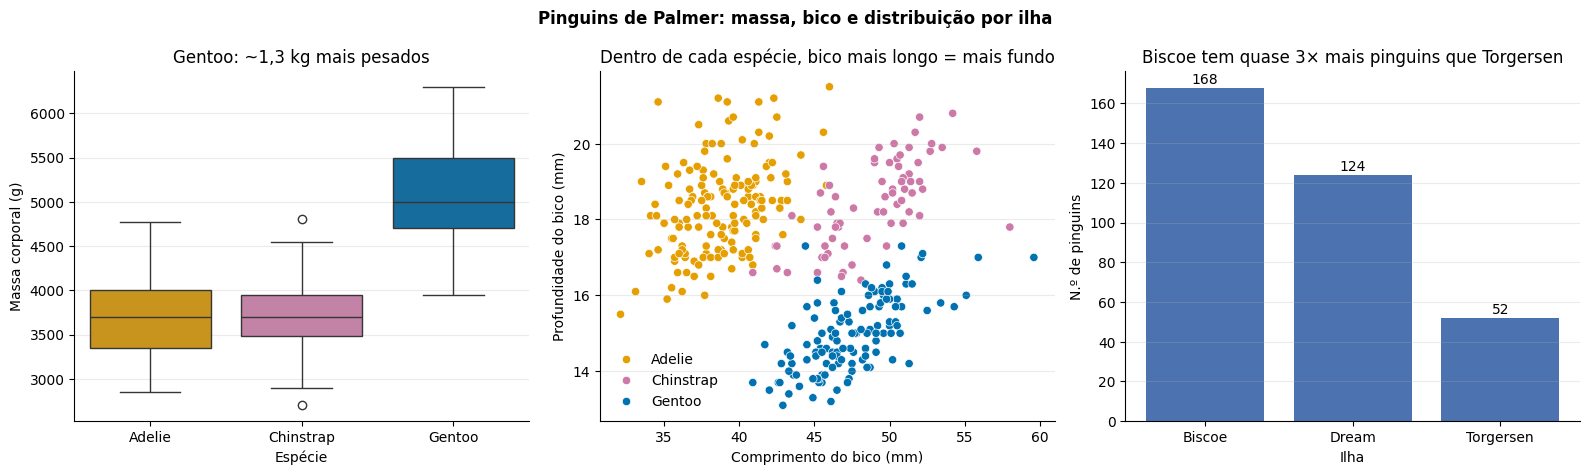

In [ ]:
fig, axs = plt.subplots(1, 3, figsize=(16, 4.8))

# (a) Distribuição
sns.boxplot(data=pen, x='species', y='body_mass_g', order=ordem,
            hue='species', palette=cores, legend=False, ax=axs[0])
axs[0].set(title='Gentoo: ~1,3 kg mais pesados',
           xlabel='Espécie', ylabel='Massa corporal (g)')

# (b) Relação
sns.scatterplot(data=d, x='bill_length_mm', y='bill_depth_mm',
                hue='species', palette=cores, ax=axs[1])
axs[1].set(title='Dentro de cada espécie, bico mais longo = mais fundo',
           xlabel='Comprimento do bico (mm)', ylabel='Profundidade do bico (mm)')
axs[1].legend(title=None, frameon=False)

# (c) Comparação
axs[2].bar(ilhas.index, ilhas.values, color='#4C72B0')
for i, v in enumerate(ilhas.values):
    axs[2].text(i, v + 2, v, ha='center')
axs[2].set(title='Biscoe tem quase 3× mais pinguins que Torgersen',
           xlabel='Ilha', ylabel='N.º de pinguins')

# limpeza (chartjunk)
for a in axs:
    a.grid(False)
    a.yaxis.grid(True, alpha=.25)
sns.despine()
fig.suptitle('Pinguins de Palmer: massa, bico e distribuição por ilha', fontweight='bold')
fig.tight_layout()
plt.show()

# **Exercício 3**

---



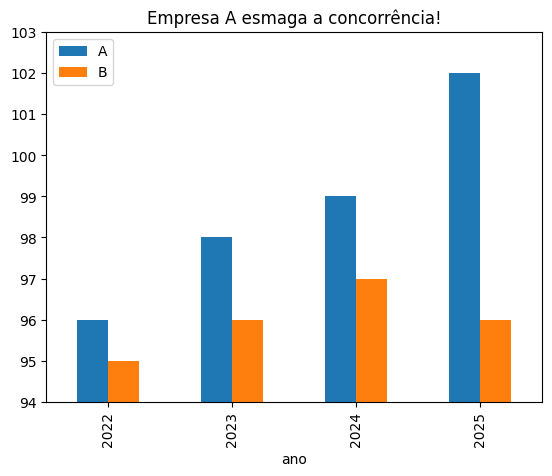

In [ ]:
vendas = pd.DataFrame({'ano': [2022, 2023, 2024, 2025],
                       'A': [96, 98, 99, 102], 'B': [95, 96, 97, 96]})
ax = vendas.plot(x='ano', y=['A', 'B'], kind='bar')
ax.set_ylim(94, 103); ax.set_title('Empresa A esmaga a concorrência!')
plt.show()

a) Liste, em Markdown, todas as distorções que identifica (há pelo menos três: eixo, título, escolha de gráfico).

As distorções identificadas são:

1. **Eixo truncado:** set_ylim(94, 103) corta a base das barras. Nas barras o .comprimento representa o valor, e aqui uma diferença de 6 unidades em ~100 parece enorme.
2. **Título tendencioso:** “esmaga a concorrência!” é uma opinião emotiva e exagerada. Uma diferença de ~6 % não esmaga ninguém.
3. **Tipo de gráfico inadequado:** a pergunta é sobre evolução no tempo, para a qual um gráfico de linhas é melhor que barras agrupadas.
4. **Falta de contexto:** os eixos não têm título nem unidades. Não se diz o que são as vendas.
5. **Janela de eixo mínima:** amplifica pequenas diferenças e não há anotação do valor real.


b) Produza a versão honesta: gráfico adequado, eixo correto, título neutro e factual, anotação da diferença real.

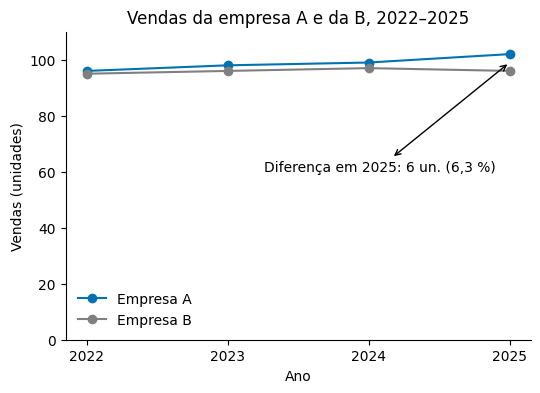

In [ ]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(vendas.ano, vendas.A, marker='o', color='#0072B2', label='Empresa A')
ax.plot(vendas.ano, vendas.B, marker='o', color='grey',    label='Empresa B')
ax.set_ylim(0, 110)                       # eixo a começar em zero
ax.set_xticks(vendas.ano)
ax.set_xlabel('Ano')
ax.set_ylabel('Vendas (unidades)')
ax.set_title('Vendas da empresa A e da B, 2022–2025')
ax.annotate('Diferença em 2025: 6 un. (6,3 %)', xy=(2025, 99), ha='right',
            xytext=(2024.9, 60), arrowprops=dict(arrowstyle='<->'))
ax.legend(frameon=False)
sns.despine()
plt.show()

Usei um gráfico de linhas porque mostra evolução no tempo. O eixo y parte do zero, por isso a diferença visual corresponde à diferença real. O título é neutro e factual. A anotação quantifica a diferença em 2025: 102 − 96 = 6 unidades, cerca de 6 % em relação a B.

c) Escreva a frase que um jornalista rigoroso escreveria a partir do gráfico corrigido.

Em 2025, a empresa A vendeu 102 unidades contra 96 da empresa B, uma diferença de cerca de 6 %. A empresa A cresceu 6 % desde 2022 (de 96 para 102), e a B manteve-se praticamente estável (de 95 para 96).

# **Exercício 4**

---



Refaça o gráfico (b) do Exercício 2 em plotly express, com hover a mostrar a espécie e as medidas. Em 2 linhas: em que contextos a interatividade compensa?



In [ ]:
import plotly.express as px

fig = px.scatter(
    d, x='bill_length_mm', y='bill_depth_mm', color='species',
    color_discrete_map=cores,
    hover_name='species',
    hover_data={'bill_length_mm': ':.1f', 'bill_depth_mm': ':.1f',
                'flipper_length_mm': True, 'body_mass_g': True,
                'species': False},
    labels={'bill_length_mm': 'Comprimento do bico (mm)',
            'bill_depth_mm': 'Profundidade do bico (mm)',
            'flipper_length_mm': 'Barbatana (mm)',
            'body_mass_g': 'Massa (g)'},
    title='Por espécie, bicos mais longos são também mais profundos')
fig.show()

A interatividade compensa na exploração de muitos pontos (identificar outliers, ler valores exatos) e em dashboards ou relatórios online, onde o leitor quer ir ao detalhe. Não compensa em papel, slides ou artigos, onde o gráfico tem de se explicar sozinho e as anotações estáticas comunicam melhor.


